In [1]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

In [2]:
def compare_means(x, y, alpha=0.05, known_vars=None, equal_var=False):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    n1, n2 = len(x), len(y)
    mean_diff = x.mean() - y.mean()

    if known_vars is not None:
        var1, var2 = known_vars
        statistic = mean_diff / np.sqrt(
            var1 / n1 + var2 / n2
        )
        p_value = 2 * stats.norm.sf(abs(statistic))
        test_name = "Z-test"
    else:
        result = stats.ttest_ind(x, y, equal_var=equal_var)
        statistic = result.statistic
        p_value = result.pvalue
        test_name = "Student t-test"

    return {
        "test": test_name,
        "mean_x": x.mean(),
        "mean_y": y.mean(),
        "difference": mean_diff,
        "statistic": statistic,
        "p_value": p_value,
        "reject_h0": p_value < alpha
    }

In [3]:
def get_cases():
    return [
        {
            "name": "Z-test: известные дисперсии",
            "mu1": 10, "mu2": 10,
            "sigma1": 2, "sigma2": 2,
            "known_vars": (4, 4),
        },
        {
            "name": "Z-test: известные дисперсии, разные средние",
            "mu1": 10, "mu2": 11,
            "sigma1": 2, "sigma2": 2,
            "known_vars": (4, 4),
        },
        {
            "name": "Student t-test: неизвестные равные дисперсии",
            "mu1": 10, "mu2": 10,
            "sigma1": 2, "sigma2": 2,
            "known_vars": None,
        },
        {
            "name": "Student t-test: неизвестные равные дисперсии, разные средние",
            "mu1": 10, "mu2": 11,
            "sigma1": 2, "sigma2": 2,
            "known_vars": None,
        },
    ]

In [4]:
def run_experiments():
    sample_sizes = [10, 100, 1000, 10000]
    alpha = 0.05
    cases = get_cases()

    for case_index, case in enumerate(cases):
        print("\n" + "=" * 105)
        print(case["name"])
        print(
            f"mu1={case['mu1']}, mu2={case['mu2']}, "
            f"sigma1={case['sigma1']}, sigma2={case['sigma2']}"
        )
        print("-" * 105)
        print(
            f"{'n':>7} {'mean_x':>12} {'mean_y':>12} "
            f"{'difference':>12} {'statistic':>12} "
            f"{'p-value':>14} {'decision':^20}"
        )
        print("-" * 105)

        for n in sample_sizes:
            rng = np.random.default_rng(
                1000 * (case_index + 1) + n
            )

            x = rng.normal(case["mu1"], case["sigma1"], n)
            y = rng.normal(case["mu2"], case["sigma2"], n)

            result = compare_means(
                x, y,
                alpha=alpha,
                known_vars=case["known_vars"],
                equal_var=True
            )

            decision = (
                "Отвергаем H0"
                if result["reject_h0"]
                else "Не отвергаем H0"
            )

            print(
                f"{n:7d} "
                f"{result['mean_x']:12.4f} "
                f"{result['mean_y']:12.4f} "
                f"{result['difference']:12.4f} "
                f"{result['statistic']:12.4f} "
                f"{result['p_value']:14.6g} "
                f"{decision:^20}"
            )

        print("-" * 105)

In [5]:
def plot_statistic_distributions():
    sample_sizes = [10, 100, 1000, 10000]
    repetitions = 5000
    cases = get_cases()

    for case_index, case in enumerate(cases):
        fig, axes = plt.subplots(
            2, 2, figsize=(12, 8),
            constrained_layout=True
        )
        fig.suptitle(case["name"])

        for ax, n in zip(axes.flat, sample_sizes):
            rng = np.random.default_rng(
                1000 * (case_index + 1) + n
            )

            x = rng.normal(
                case["mu1"], case["sigma1"],
                size=(repetitions, n)
            )
            y = rng.normal(
                case["mu2"], case["sigma2"],
                size=(repetitions, n)
            )

            mean_diff = x.mean(axis=1) - y.mean(axis=1)

            if case["known_vars"] is not None:
                var1, var2 = case["known_vars"]
                se = np.sqrt(var1 / n + var2 / n)
                statistic = mean_diff / se
                grid = np.linspace(
                    statistic.min(), statistic.max(), 500
                )

                ax.plot(
                    grid, stats.norm.pdf(grid),
                    linestyle="--",
                    label="N(0, 1) при H0"
                )
                statistic_name = "Z"

            else:
                var_x = x.var(axis=1, ddof=1)
                var_y = y.var(axis=1, ddof=1)

                pooled_var = (
                    (n - 1) * var_x + (n - 1) * var_y
                ) / (2 * n - 2)

                statistic = mean_diff / np.sqrt(
                    pooled_var * (2 / n)
                )

                grid = np.linspace(
                    statistic.min(), statistic.max(), 500
                )

                ax.plot(
                    grid, stats.t.pdf(grid, 2 * n - 2),
                    linestyle="--",
                    label="t-распределение при H0"
                )
                statistic_name = "t"

            ax.hist(
                statistic,
                bins=50,
                density=True,
                alpha=0.65,
                label="Эмпирическое распределение"
            )

            ax.axvline(0, linestyle=":", color="black")
            ax.set_title(f"n = {n}")
            ax.set_xlabel(f"Статистика {statistic_name}")
            ax.set_ylabel("Плотность")
            ax.legend(fontsize=8)
            ax.grid(alpha=0.2)

        plt.show()


Z-test: известные дисперсии
mu1=10, mu2=10, sigma1=2, sigma2=2
---------------------------------------------------------------------------------------------------------
      n       mean_x       mean_y   difference    statistic        p-value       decision      
---------------------------------------------------------------------------------------------------------
     10       9.4910      10.3031      -0.8121      -0.9079       0.363917   Не отвергаем H0   
    100       9.9903      10.0482      -0.0579      -0.2046       0.837895   Не отвергаем H0   
   1000       9.9275      10.1062      -0.1787      -1.9981      0.0457047     Отвергаем H0    
  10000      10.0172      10.0162       0.0010       0.0350       0.972081   Не отвергаем H0   
---------------------------------------------------------------------------------------------------------

Z-test: известные дисперсии, разные средние
mu1=10, mu2=11, sigma1=2, sigma2=2
----------------------------------------------------------

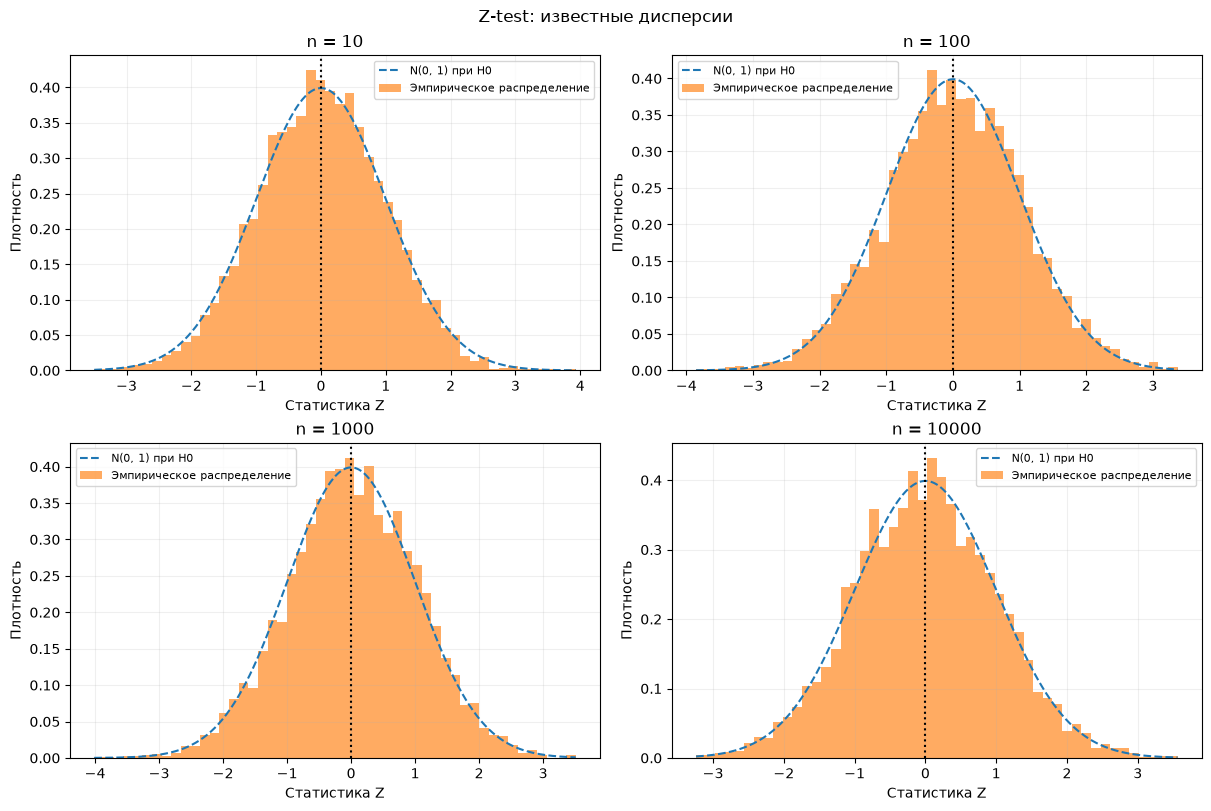

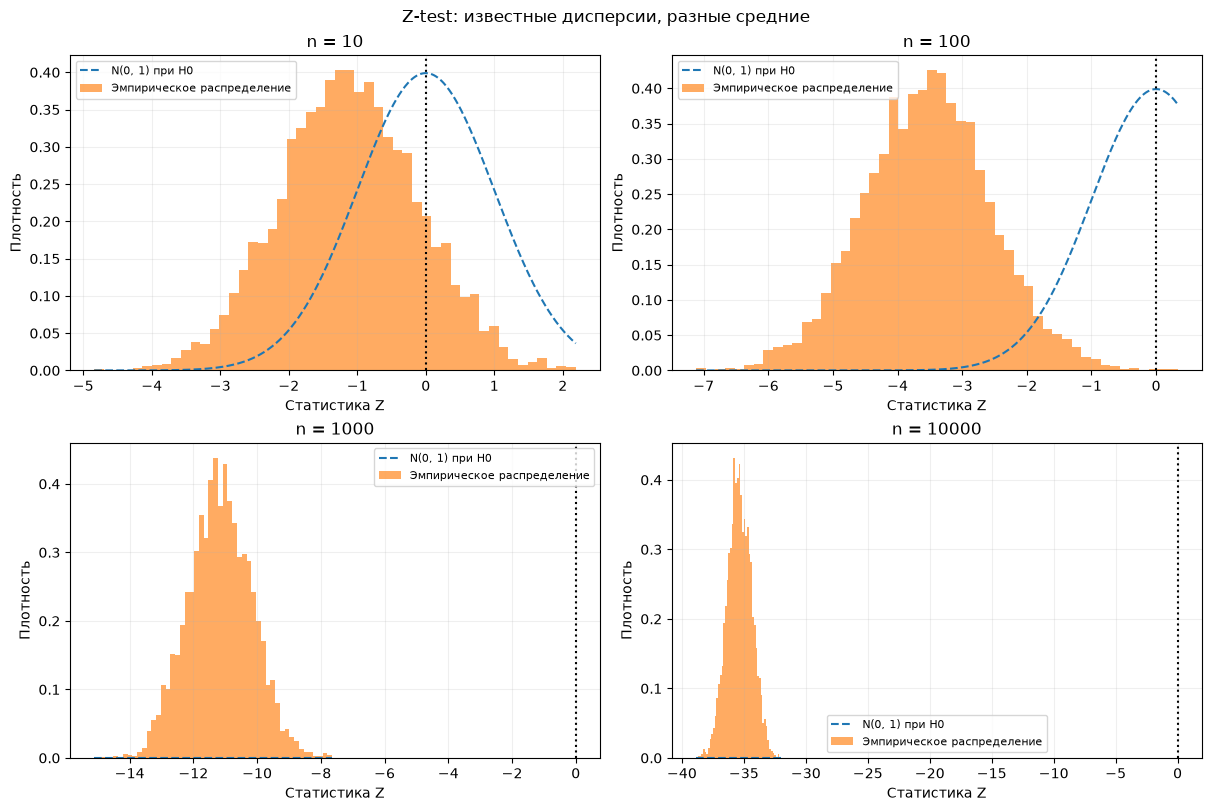

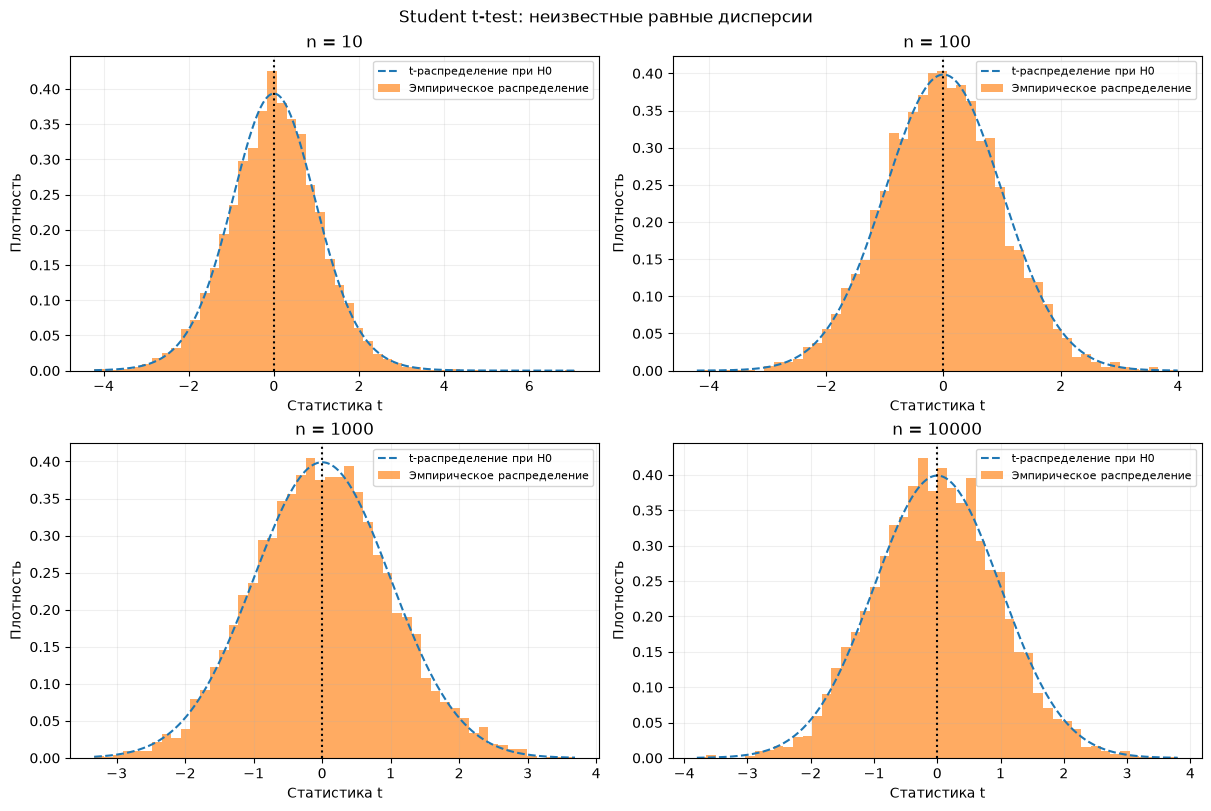

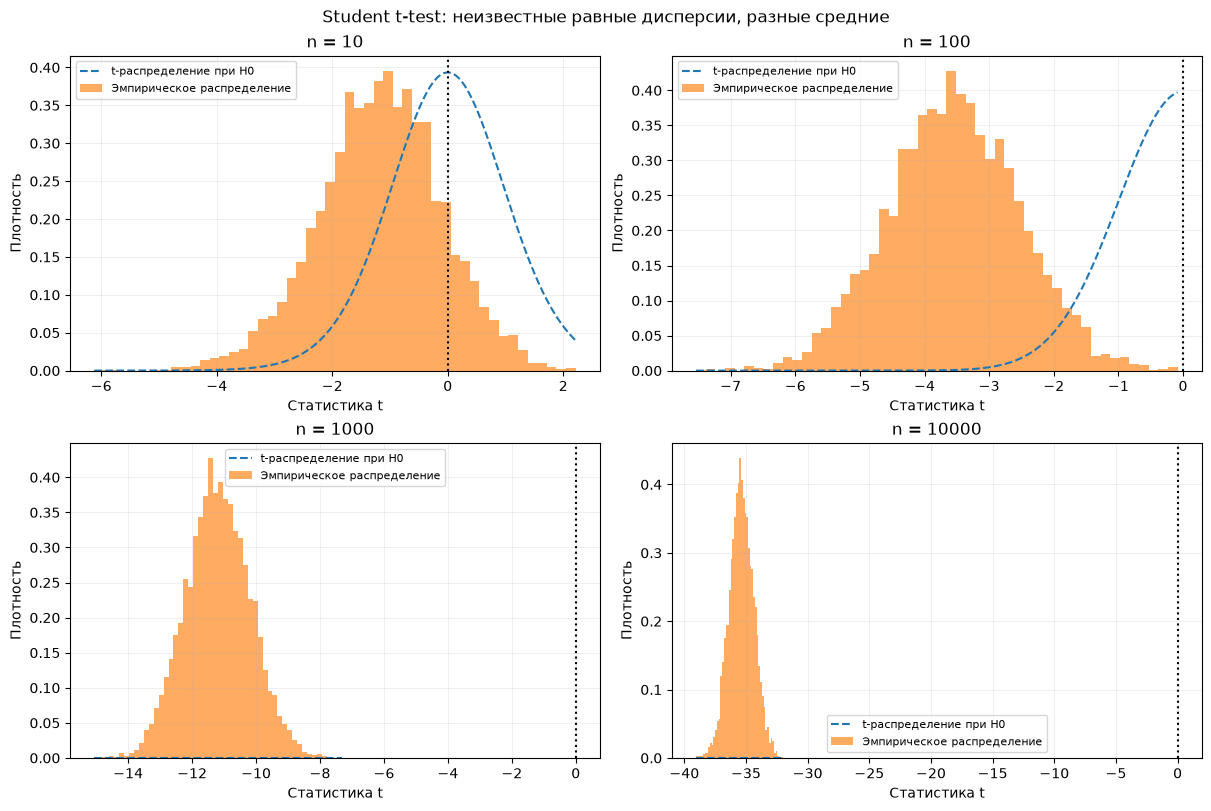

In [6]:
run_experiments()
plot_statistic_distributions()